# Módulo 4 · Ejercicio 1 · Opción A
## Telemetría IoT en tiempo real e ingesta en Delta Lake

Pipeline de **Spark Structured Streaming** que lee telemetría de vehículos (GPS,
velocidad y nivel de batería) desde un directorio de ficheros JSON, la parsea,
limpia las anomalías y la guarda en una tabla **Delta Lake particionada por ciudad**.

### De dónde salen los datos

La base es el **[Vehicle Energy Dataset](https://github.com/gsoh/VED)** (Universidad
de Michigan, licencia Apache-2.0): 27 coches eléctricos reales medidos por OBD-II a
1 registro por segundo en Ann Arbor, Michigan. De ahí salen las tres señales que
pide el enunciado (posición GPS, `Vehicle Speed[km/h]` y `HV Battery SOC[%]`),
medidas de verdad y no inventadas.

El enunciado pide datos *simulados*, así que `generador.py` monta una flota
multi-ciudad encima de esos datos reales. Cambia dos cosas y solo dos:

1. **La geografía.** VED es de una sola ciudad y particionar por ciudad no tendría
   ninguna gracia. Cada vehículo se asigna a una de 5 ciudades españolas y su
   recorrido se traslada allí.
2. **El tamaño de la flota.** Solo 27 coches miden la batería, que entre 5 ciudades
   salen a 5 por ciudad. Se usa el **viaje** como unidad: cada viaje real pasa a ser
   un coche distinto, lo que da 1.590 vehículos. Vale porque entre viajes el coche
   se recarga, o sea que un viaje ya es independiente del anterior.

La velocidad y la batería no se tocan en ningún momento.

Los viajes reales duran hasta 96 minutos y aquí se reproducen 60 veces más rápido,
así que el más largo ocupa poco más de un minuto. A escala real, un solo evento del
final de un viaje largo empujaría el reloj interno de Spark casi una hora hacia
delante y el resto se descartaría por atrasado.

El generador estropea a propósito una parte de los registros y apunta cuáles en un
manifiesto. Cada registro recibe como mucho un fallo, así que al final se puede
comparar cifra contra cifra lo que se rompió y lo que se detectó.

### El recorrido de los datos

```
generador.py  ──JSON──▶  lake/landing/
                              │
                    lectura en streaming
                              ▼
                     BRONCE   datos crudos, anomalías incluidas
                              │
                  quitar duplicados (watermark)
                              │
                       aplicar reglas
                        ╱           ╲
                    PLATA          CUARENTENA
             particionada          las filas que fallaron,
             por ciudad            con el motivo
                        ╲           ╱
                          consultas
                              ▼
                    ORO   resumen por ciudad · calidad de datos
```

---
## 1. Preparación

In [1]:
import json, os, subprocess, sys, time
from pathlib import Path

AQUI = Path.cwd()

# Hadoop tiene que estar en el PATH y no solo en HADOOP_HOME: Java carga hadoop.dll
# desde ahi. PYSPARK_PYTHON evita que Spark coja el python de la Microsoft Store.
os.environ["HADOOP_HOME"] = str(AQUI / ".hadoop")
os.environ["PATH"] = str(AQUI / ".hadoop" / "bin") + os.pathsep + os.environ["PATH"]
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

LANDING     = AQUI / "lake" / "landing"
BRONCE      = AQUI / "lake" / "bronce"
PLATA       = AQUI / "lake" / "plata"
CUARENTENA  = AQUI / "lake" / "cuarentena"
ORO_CIUDAD  = AQUI / "lake" / "oro_ciudades"
ORO_CALIDAD = AQUI / "lake" / "oro_calidad"
CHECKPOINT  = AQUI / "lake" / "checkpoints"

def ruta(p):
    """Spark en Windows necesita la ruta como file:///C:/... y no como C:\\..."""
    return p.resolve().as_uri()

CIUDADES = {
    "Madrid":    (40.4168, -3.7038),
    "Barcelona": (41.3851,  2.1734),
    "Valencia":  (39.4699, -0.3763),
    "Sevilla":   (37.3891, -5.9845),
    "Bilbao":    (43.2630, -2.9350),
}

print("proyecto:", AQUI)
print("ciudades:", ", ".join(CIUDADES))

proyecto: C:\Users\oppen\Code\UNI\ArquitecturaBigData\upv-arquitecturas-bigdata-exercises\module-4
ciudades: Madrid, Barcelona, Valencia, Sevilla, Bilbao


In [2]:
from delta import configure_spark_with_delta_pip
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = configure_spark_with_delta_pip(
    SparkSession.builder.appName("telemetria-iot").master("local[*]")
        .config("spark.sql.extensions", "io.delta.sql.DeltaSparkSessionExtension")
        .config("spark.sql.catalog.spark_catalog",
                "org.apache.spark.sql.delta.catalog.DeltaCatalog")
        # Con las 200 por defecto salen cientos de tareas vacias para tan pocos datos.
        .config("spark.sql.shuffle.partitions", "8")
        .config("spark.sql.session.timeZone", "UTC")
).getOrCreate()
spark.sparkContext.setLogLevel("ERROR")

print("Spark", spark.version)
print("Interfaz web:", spark.sparkContext.uiWebUrl)   # capturas para el informe

Spark 3.5.3
Interfaz web: http://DESKTOP-H2OIHE6:4040


---
## 2. Arrancar el generador

Escribe un fichero JSON cada 2 segundos en `lake/landing/`. Se lanza en segundo
plano para que produzca datos mientras el pipeline los consume.

También se puede lanzar a mano en otra terminal con `python generador.py`.

In [3]:
import shutil
for d in (LANDING, BRONCE, PLATA, CUARENTENA, ORO_CIUDAD, ORO_CALIDAD, CHECKPOINT):
    shutil.rmtree(d, ignore_errors=True)
LANDING.mkdir(parents=True)

generador = subprocess.Popen(
    [sys.executable, "generador.py", "--duracion", "60", "--intervalo", "2", "--tamano", "500"],
    cwd=AQUI, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT,
)
print("generador arrancado (60 segundos)")
time.sleep(20)   # que le de tiempo a escribir los primeros ficheros
print(f"{len(list(LANDING.glob('*.json')))} ficheros escritos hasta ahora")

generador arrancado (60 segundos)


9 ficheros escritos hasta ahora


---
## 3. Capa Bronce: los datos tal y como llegan

Bronce guarda **exactamente lo que llegó**, anomalías incluidas. Así se puede
reprocesar más adelante con otras reglas de limpieza sin volver a pedir nada al
origen.

Dos decisiones:

- **El esquema se escribe a mano.** En streaming nunca se deja que Spark lo deduzca:
  tendría que leer los datos en cada vuelta para averiguarlo, y el esquema podría
  cambiar de un fichero a otro sin que nadie se entere.
- **`event_ts` se declara como texto**, no como fecha. Si fuese fecha, Spark
  convertiría en `null` cualquier valor mal formado y ya no se podría distinguir
  "no llegó la fecha" de "llegó una fecha inválida". La conversión se hace luego.

In [4]:
from pyspark.sql.types import DoubleType, StringType, StructField, StructType

ESQUEMA = StructType([
    StructField("event_id",    StringType()),
    StructField("vehicle_id",  StringType()),
    StructField("city",        StringType()),
    StructField("event_ts",    StringType()),
    StructField("lat",         DoubleType()),
    StructField("lon",         DoubleType()),
    StructField("speed_kmh",   DoubleType()),
    StructField("battery_pct", DoubleType()),
    StructField("trip_id",     StringType()),
])

bronce = (
    spark.readStream.format("json")
        .schema(ESQUEMA)
        # Sin esto la primera vuelta se traga de golpe todo lo que haya.
        .option("maxFilesPerTrigger", 3)
        .load(ruta(LANDING))
        .withColumn("_recibido", F.current_timestamp())
        .withColumn("_fichero", F.input_file_name())
)

consulta_bronce = (
    bronce.writeStream.format("delta").outputMode("append")
        .queryName("landing_a_bronce")
        .option("checkpointLocation", ruta(CHECKPOINT / "bronce"))
        .trigger(processingTime="5 seconds")
        .start(ruta(BRONCE))
)

# Una tabla Delta recien creada no tiene esquema hasta el primer lote: sin esperar,
# el paso siguiente falla con DELTA_SCHEMA_NOT_SET.
while not (consulta_bronce.lastProgress and consulta_bronce.lastProgress["numInputRows"] > 0):
    time.sleep(2)
print(f"bronce en marcha, primer lote de {consulta_bronce.lastProgress['numInputRows']} filas")

bronce en marcha, primer lote de 1522 filas


---
## 4. Capa Plata: limpieza y partición por ciudad

### Las reglas

Cada fila se comprueba contra seis reglas. Las que fallan alguna van a
**cuarentena** con la lista de motivos; las que pasan todas van a **plata**.

| Regla | Se rechaza cuando | Etiqueta |
|---|---|---|
| Velocidad | vacía, negativa o mayor de 200 km/h | `VELOCIDAD_ABSURDA` |
| Coordenadas | vacías o fuera del rango de la Tierra | `COORDENADA_IMPOSIBLE` |
| Coherencia | el punto está a más de 0,5° del centro de su ciudad | `FUERA_DE_CIUDAD` |
| Batería | vacía, negativa o mayor de 100 | `BATERIA_FUERA_DE_RANGO` |
| Claves | falta el vehículo, la ciudad o la fecha | `CAMPO_VACIO` |
| Ciudad | la ciudad no es ninguna de las cinco | `CIUDAD_DESCONOCIDA` |

Las etiquetas son **las mismas** que usa el generador al estropear los datos. Eso
permite comparar al final, uno a uno, lo que se rompió contra lo que se detectó.

Una fila puede incumplir varias reglas a la vez y se apuntan todas, no solo la
primera.

`FUERA_DE_CIUDAD` solo se comprueba si las coordenadas son válidas: no tiene
sentido medir a qué distancia de Madrid está un punto con latitud 999.

In [5]:
MAX_VELOCIDAD = 200.0
RADIO_CIUDAD  = 0.5     # grados alrededor del centro de la ciudad

def marcar_problemas(df):
    """Anade la columna `problemas` con las reglas que incumple cada fila."""
    lat_centro = F.create_map(*[x for ciudad, (la, lo) in CIUDADES.items()
                                for x in (F.lit(ciudad), F.lit(la))])[F.col("city")]
    lon_centro = F.create_map(*[x for ciudad, (la, lo) in CIUDADES.items()
                                for x in (F.lit(ciudad), F.lit(lo))])[F.col("city")]

    coords_rotas = (F.col("lat").isNull() | F.col("lon").isNull()
                    | ~F.col("lat").between(-90, 90)
                    | ~F.col("lon").between(-180, 180))

    lejos = (~coords_rotas
             & ((F.abs(F.col("lat") - lat_centro) > RADIO_CIUDAD)
                | (F.abs(F.col("lon") - lon_centro) > RADIO_CIUDAD)))

    reglas = [
        (F.col("speed_kmh").isNull() | ~F.col("speed_kmh").between(0, MAX_VELOCIDAD),
         "VELOCIDAD_ABSURDA"),
        (coords_rotas, "COORDENADA_IMPOSIBLE"),
        (lejos, "FUERA_DE_CIUDAD"),
        (F.col("battery_pct").isNull() | ~F.col("battery_pct").between(0, 100),
         "BATERIA_FUERA_DE_RANGO"),
        (F.col("vehicle_id").isNull() | F.col("city").isNull() | F.col("event_ts").isNull(),
         "CAMPO_VACIO"),
        (F.col("city").isNotNull() & ~F.col("city").isin(list(CIUDADES)),
         "CIUDAD_DESCONOCIDA"),
    ]
    # Vacia y no null: size(null) devuelve -1 y romperia el filtro de despues.
    return df.withColumn("problemas", F.array_compact(
        F.array(*[F.when(cond, F.lit(etiqueta)) for cond, etiqueta in reglas])))


def anadir_columnas(df):
    """Columnas calculadas que solo tienen sentido sobre datos ya limpios."""
    return (df
        .withColumn("en_movimiento", F.col("speed_kmh") > 1.0)
        .withColumn("nivel_bateria",
                    F.when(F.col("battery_pct") < 10, "CRITICO")
                     .when(F.col("battery_pct") < 25, "BAJO")
                     .when(F.col("battery_pct") < 60, "MEDIO")
                     .otherwise("ALTO")))

print("reglas definidas")

reglas definidas


### Duplicados y eventos que llegan tarde

```python
.withWatermark("event_ts", "10 minutes").dropDuplicates(["event_id"])
```

El watermark es lo que permite a Spark olvidar los eventos viejos que guarda para
detectar duplicados. Sin él esa memoria crece sin parar.

El precio es que los eventos que llegan con más de 10 minutos de retraso se
descartan sin avisar. Por eso al final **bronce no es exactamente plata más
cuarentena**, y esa diferencia hay que medirla en vez de darla por buena.

### Dos tablas desde un solo flujo

`writeStream` solo admite un destino, pero necesitamos escribir plata **y**
cuarentena. `foreachBatch` da acceso a cada lote ya calculado y dentro se puede
escribir tantas veces como haga falta.

In [6]:
def guardar(lote, lote_id):
    """Parte cada lote en dos y escribe las dos tablas Delta."""
    # Se recorre dos veces. Sin cachear, Spark releeria el JSON en cada escritura.
    lote.persist()
    try:
        limpias = anadir_columnas(lote.filter(F.size("problemas") == 0)).drop("problemas")
        sucias  = lote.filter(F.size("problemas") > 0)

        limpias.write.format("delta").mode("append").partitionBy("city").save(ruta(PLATA))
        sucias.write.format("delta").mode("append").save(ruta(CUARENTENA))
    finally:
        lote.unpersist()


entrada_plata = marcar_problemas(
    spark.readStream.format("delta").load(ruta(BRONCE))
        .withColumn("event_ts", F.to_timestamp("event_ts"))
        .withWatermark("event_ts", "10 minutes")
        .dropDuplicates(["event_id"])
)

consulta_plata = (
    entrada_plata.writeStream
        .foreachBatch(guardar)
        .queryName("bronce_a_plata")
        # Un checkpoint por consulta: compartirlo corrompe el avance de las dos.
        .option("checkpointLocation", ruta(CHECKPOINT / "plata"))
        .trigger(processingTime="5 seconds")
        .start()
)
print("plata en marcha")

plata en marcha


### Seguimiento en vivo

Mientras esta celda corre conviene abrir la interfaz de Spark (el enlace de la
celda 2), pestaña **Structured Streaming**: de ahí salen las capturas del informe.
Hay que hacerlas **ahora**, porque esa página desaparece al cerrar Spark.

In [7]:
progreso = {}   # se guarda para la grafica del final

for i in range(16):
    time.sleep(5)
    linea = []
    for q in (consulta_bronce, consulta_plata):
        p = q.lastProgress
        if p and p["numInputRows"] > 0:
            progreso.setdefault(q.name, {})[p["batchId"]] = p
            linea.append(f"{q.name}: lote {p['batchId']} - {p['numInputRows']} filas"
                         f" - {p['durationMs'].get('triggerExecution', 0)} ms")
    print(f"[{i*5:>3}s] " + (" | ".join(linea) if linea else "esperando datos"))

[  0s] landing_a_bronce: lote 1 - 1523 filas - 5680 ms


[  5s] landing_a_bronce: lote 3 - 1020 filas - 2421 ms | bronce_a_plata: lote 0 - 3045 filas - 9754 ms


[ 10s] landing_a_bronce: lote 4 - 1528 filas - 2201 ms | bronce_a_plata: lote 1 - 2536 filas - 2688 ms


[ 15s] landing_a_bronce: lote 5 - 1524 filas - 2472 ms | bronce_a_plata: lote 2 - 1528 filas - 2775 ms


[ 20s] landing_a_bronce: lote 6 - 1524 filas - 2481 ms | bronce_a_plata: lote 3 - 1524 filas - 2760 ms


[ 25s] landing_a_bronce: lote 7 - 507 filas - 2379 ms | bronce_a_plata: lote 4 - 1524 filas - 2650 ms


... (6 outputs left out)

[ 60s] esperando datos


[ 65s] esperando datos


[ 70s] esperando datos


[ 75s] esperando datos


In [8]:
# Primero el consumidor, luego el productor, para no dejar lotes a medias.
for q in (consulta_plata, consulta_bronce):
    q.stop()
    print("parada:", q.name)
generador.wait(timeout=30)
print("generador terminado")

parada: bronce_a_plata
parada: landing_a_bronce
generador terminado


---
## 5. Compactar las tablas

El streaming escribe al menos un fichero por lote y por partición: con lotes de 5
segundos salen decenas de ficheros de pocos KB, y leerlos cuesta más en abrirlos
que en leer los datos. `OPTIMIZE` los junta y `ZORDER` coloca juntas las filas del
mismo vehículo para que las consultas puedan saltarse ficheros enteros.

In [9]:
def ficheros_activos(tabla):
    # Los que usa ahora. Los .parquet viejos siguen en disco hasta el VACUUM.
    return spark.sql(f"DESCRIBE DETAIL delta.`{ruta(tabla)}`").collect()[0]["numFiles"]

antes = ficheros_activos(PLATA)
spark.sql(f"OPTIMIZE delta.`{ruta(PLATA)}` ZORDER BY (vehicle_id, event_ts)")
spark.sql(f"OPTIMIZE delta.`{ruta(CUARENTENA)}`")
despues = ficheros_activos(PLATA)

en_disco = len(list(PLATA.rglob("*.parquet")))
print(f"ficheros que usa plata: {antes} antes -> {despues} despues del OPTIMIZE")
print(f"ficheros que hay en disco: {en_disco} (los viejos esperan a un VACUUM)")

ficheros que usa plata: 360 antes -> 5 despues del OPTIMIZE
ficheros que hay en disco: 365 (los viejos esperan a un VACUUM)


---
## 6. Capa Oro: las consultas

Se calcula en lote y no en streaming: los kilómetros recorridos necesitan comparar
cada punto con el anterior del mismo vehículo (`lag`), y esa función no está
permitida dentro de una agregación en streaming.

La distancia se calcula con la **fórmula de haversine** y no restando grados: un
grado de longitud mide unos 81 km en Bilbao y unos 88 en Sevilla, así que restar
grados metería un error distinto en cada ciudad, justo en la dimensión por la que
estamos agrupando.

In [10]:
from pyspark.sql import Window

plata = spark.read.format("delta").load(ruta(PLATA))

def haversine(lat1, lon1, lat2, lon2):
    """Distancia en km entre dos puntos de la Tierra."""
    a = (F.sin(F.radians(lat2 - lat1) / 2) ** 2
         + F.cos(F.radians(lat1)) * F.cos(F.radians(lat2))
         * F.sin(F.radians(lon2 - lon1) / 2) ** 2)
    return F.lit(2 * 6371.0088) * F.asin(F.sqrt(a))

orden = Window.partitionBy("vehicle_id", "trip_id").orderBy("event_ts")

con_distancia = (
    plata
    .withColumn("lat_ant", F.lag("lat").over(orden))
    .withColumn("lon_ant", F.lag("lon").over(orden))
    .withColumn("tramo_km", F.when(F.col("lat_ant").isNull(), F.lit(0.0))
                             .otherwise(haversine(F.col("lat_ant"), F.col("lon_ant"),
                                                  F.col("lat"), F.col("lon"))))
    # Mas de 1 km entre dos medidas de 1 Hz son 3.600 km/h: es un hueco en la
    # grabacion, no un desplazamiento.
    .withColumn("tramo_km", F.when(F.col("tramo_km") > 1.0, F.lit(0.0))
                             .otherwise(F.col("tramo_km")))
)

oro_ciudades = (
    con_distancia.groupBy("city").agg(
        F.count("*").alias("eventos"),
        F.countDistinct("vehicle_id").alias("vehiculos"),
        F.round(F.sum("tramo_km"), 1).alias("km_recorridos"),
        F.round(F.avg("speed_kmh"), 1).alias("velocidad_media"),
        F.round(F.avg(F.when(F.col("en_movimiento"), F.col("speed_kmh"))), 1)
         .alias("velocidad_en_marcha"),
        F.round(F.max("speed_kmh"), 1).alias("velocidad_maxima"),
        F.round(F.avg("battery_pct"), 1).alias("bateria_media"),
        F.round(100.0 * F.avg(F.when(F.col("nivel_bateria") == "CRITICO", 1.0)
                               .otherwise(0.0)), 1).alias("pct_bateria_critica"),
    ).orderBy("city")
)

oro_ciudades.write.format("delta").mode("overwrite").save(ruta(ORO_CIUDAD))
oro_ciudades.show(truncate=False)

+---------+-------+---------+-------------+---------------+-------------------+----------------+-------------+-------------------+
|city     |eventos|vehiculos|km_recorridos|velocidad_media|velocidad_en_marcha|velocidad_maxima|bateria_media|pct_bateria_critica|
+---------+-------+---------+-------------+---------------+-------------------+----------------+-------------+-------------------+
|Barcelona|2882   |307      |684.7        |40.9           |45.2               |124.6           |31.1         |49.1               |
|Bilbao   |2651   |300      |592.8        |38.7           |43.6               |132.8           |30.4         |52.1               |
|Madrid   |2731   |295      |620.9        |39.2           |43.5               |131.9           |31.9         |48.0               |
|Sevilla  |2709   |309      |634.5        |39.0           |43.7               |128.1           |36.7         |43.6               |
|Valencia |2650   |300      |620.4        |38.8           |43.6               |120.

In [11]:
cuarentena = spark.read.format("delta").load(ruta(CUARENTENA))

oro_calidad = (
    cuarentena
    .withColumn("motivo", F.explode("problemas"))
    .withColumn("city", F.coalesce("city", F.lit("(sin ciudad)")))
    .groupBy("motivo", "city").agg(F.count("*").alias("filas"))
    .orderBy(F.desc("filas"))
)

oro_calidad.write.format("delta").mode("overwrite").save(ruta(ORO_CALIDAD))
oro_calidad.show(truncate=False)

+----------------------+------------+-----+
|motivo                |city        |filas|
+----------------------+------------+-----+
|VELOCIDAD_ABSURDA     |Sevilla     |73   |
|CAMPO_VACIO           |(sin ciudad)|71   |
|CIUDAD_DESCONOCIDA    |Lisboa      |62   |
|VELOCIDAD_ABSURDA     |Bilbao      |60   |
|BATERIA_FUERA_DE_RANGO|Barcelona   |58   |
|VELOCIDAD_ABSURDA     |Barcelona   |55   |
|BATERIA_FUERA_DE_RANGO|Valencia    |53   |
|VELOCIDAD_ABSURDA     |Valencia    |52   |
|COORDENADA_IMPOSIBLE  |Madrid      |47   |
|BATERIA_FUERA_DE_RANGO|Madrid      |46   |
|COORDENADA_IMPOSIBLE  |Barcelona   |46   |
|CIUDAD_DESCONOCIDA    |Toulouse    |44   |
|COORDENADA_IMPOSIBLE  |Bilbao      |44   |
|CAMPO_VACIO           |Valencia    |43   |
|VELOCIDAD_ABSURDA     |Madrid      |43   |
|COORDENADA_IMPOSIBLE  |Valencia    |39   |
|BATERIA_FUERA_DE_RANGO|Sevilla     |38   |
|CIUDAD_DESCONOCIDA    |Oporto      |38   |
|FUERA_DE_CIUDAD       |Madrid      |37   |
|CAMPO_VACIO           |Sevilla 

---
## 7. Comprobaciones

### 7.1 ¿Cuadran las filas?

La cuenta que tiene que salir:

```
bronce = plata + cuarentena + duplicados quitados + descartados por llegar tarde
```

La última parte no se puede medir directamente, porque Spark descarta los eventos
atrasados sin decir nada, así que se obtiene por diferencia y se compara con los
`EVENTO_TARDIO` que el generador inyectó. Si se parecen, cuadra.

In [12]:
import itertools

manifiesto = [json.loads(l) for l in
              (LANDING / "_manifiesto.jsonl").read_text(encoding="utf-8").splitlines()]
roto = {}
for entrada in manifiesto:
    for motivo, n in entrada["anomalias"].items():
        roto[motivo] = roto.get(motivo, 0) + n
n_generadas = sum(e["filas"] for e in manifiesto)

bronce_tabla = spark.read.format("delta").load(ruta(BRONCE))
n_bronce = bronce_tabla.count()
n_plata  = plata.count()
n_cuar   = cuarentena.count()
n_dup    = n_bronce - bronce_tabla.select("event_id").distinct().count()
resto    = n_bronce - n_plata - n_cuar - n_dup

print(f"  generadas por el generador  {n_generadas:>8,}")
print(f"  leidas en bronce            {n_bronce:>8,}"
      f"   {'(todas)' if n_bronce == n_generadas else '(quedaron ficheros sin leer)'}")
print()
print(f"  plata                       {n_plata:>8,}")
print(f"  cuarentena                  {n_cuar:>8,}")
print(f"  duplicados quitados         {n_dup:>8,}")
print(f"  {'-'*38}")
print(f"  diferencia                  {resto:>8,}   <- descartados por el watermark")
print(f"  eventos tardios inyectados  {roto.get('EVENTO_TARDIO', 0):>8,}   <- deberia parecerse")

  generadas por el generador    15,237
  leidas en bronce              15,237   (todas)

  plata                         13,623
  cuarentena                     1,237
  duplicados quitados              237
  --------------------------------------
  diferencia                       140   <- descartados por el watermark
  eventos tardios inyectados       227   <- deberia parecerse


### 7.2 ¿Está particionado por ciudad?

Es el requisito literal del enunciado: en disco tiene que haber una carpeta por
ciudad.

In [13]:
carpetas = sorted(p.name for p in PLATA.iterdir() if p.name.startswith("city="))
print("carpetas en disco:", carpetas)
plata.groupBy("city").count().orderBy("city").show()

carpetas en disco: ['city=Barcelona', 'city=Bilbao', 'city=Madrid', 'city=Sevilla', 'city=Valencia']


+---------+-----+
|     city|count|
+---------+-----+
|Barcelona| 2882|
|   Bilbao| 2651|
|   Madrid| 2731|
|  Sevilla| 2709|
| Valencia| 2650|
+---------+-----+



### 7.3 ¿Está plata realmente limpia?

Se vuelven a aplicar las reglas sobre la tabla ya escrita. Si la limpieza es
correcta, **ninguna fila** debe incumplir nada.

In [14]:
malas = marcar_problemas(plata).filter(F.size("problemas") > 0).count()
print(f"filas de plata que incumplen alguna regla: {malas}")
print("CORRECTO" if malas == 0 else "MAL: alguna regla no funciona")

filas de plata que incumplen alguna regla: 0
CORRECTO


### 7.4 ¿Se detectó lo que se rompió?

La comprobación central. El generador apuntó en `_manifiesto.jsonl` cada registro
que estropeó; aquí se compara contra lo que el pipeline apartó.

Como cada registro se estropea con un solo fallo, las cifras deben **coincidir
exactamente** en las seis reglas.

Las otras dos etiquetas no aparecen en cuarentena, y es lo esperado:

- **`DUPLICADO`** lo quita `dropDuplicates`, no las reglas. Sale en la fila de
  duplicados de la comprobación 7.1.
- **`EVENTO_TARDIO`** genera filas **válidas**: lo que pone a prueba es el
  watermark, no la limpieza. Sale en la diferencia de la comprobación 7.1.

In [15]:
detectado = {r["motivo"]: r["filas"] for r in
             oro_calidad.groupBy("motivo").agg(F.sum("filas").alias("filas")).collect()}

print(f"{'motivo':<24}{'roto':>8}{'detectado':>12}")
print("-" * 44)
for motivo in sorted(set(roto) | set(detectado)):
    esperado, real = roto.get(motivo, 0), detectado.get(motivo, 0)
    if motivo == "DUPLICADO":
        nota = "  lo quita dropDuplicates"
    elif motivo == "EVENTO_TARDIO":
        nota = "  lo descarta el watermark"
    else:
        nota = "  OK" if esperado == real else f"  ojo: faltan {esperado - real}"
    print(f"{motivo:<24}{esperado:>8}{real:>12}{nota}")

motivo                      roto   detectado
--------------------------------------------
BATERIA_FUERA_DE_RANGO       230         230  OK
CAMPO_VACIO                  225         225  OK
CIUDAD_DESCONOCIDA           144         144  OK
COORDENADA_IMPOSIBLE         205         205  OK
DUPLICADO                    237           0  lo quita dropDuplicates
EVENTO_TARDIO                227           0  lo descarta el watermark
FUERA_DE_CIUDAD              150         150  OK
VELOCIDAD_ABSURDA            283         283  OK


---
## 8. Lo que aporta Delta Lake

Cada escritura es una transacción numerada. Eso permite ver qué pasó y volver a
cualquier estado anterior, cosa que con ficheros Parquet sueltos no se puede.

In [16]:
historial = spark.sql(f"DESCRIBE HISTORY delta.`{ruta(PLATA)}`")
historial.select("version", "operation", "operationMetrics").show(8, truncate=60)

ultima = historial.agg(F.max("version")).collect()[0][0]
print("la misma tabla en distintos momentos:")
for v in (0, ultima // 2, ultima):
    n = spark.read.format("delta").option("versionAsOf", v).load(ruta(PLATA)).count()
    print(f"  version {v:>2} -> {n:>8,} filas")

+-------+---------+------------------------------------------------------------+
|version|operation|                                            operationMetrics|
+-------+---------+------------------------------------------------------------+
|      9| OPTIMIZE|{numRemovedFiles -> 360, numRemovedBytes -> 2686349, p25F...|
|      8|    WRITE|{numFiles -> 40, numOutputRows -> 1350, numOutputBytes ->...|
|      7|    WRITE|{numFiles -> 40, numOutputRows -> 1361, numOutputBytes ->...|
|      6|    WRITE|{numFiles -> 40, numOutputRows -> 1365, numOutputBytes ->...|
|      5|    WRITE|{numFiles -> 40, numOutputRows -> 449, numOutputBytes -> ...|
|      4|    WRITE|{numFiles -> 40, numOutputRows -> 1342, numOutputBytes ->...|
|      3|    WRITE|{numFiles -> 40, numOutputRows -> 1357, numOutputBytes ->...|
|      2|    WRITE|{numFiles -> 40, numOutputRows -> 1358, numOutputBytes ->...|
+-------+---------+------------------------------------------------------------+
only showing top 8 rows

la 

  version  0 ->    2,738 filas


  version  4 ->    9,098 filas


  version  9 ->   13,623 filas


---
## 9. Rendimiento del flujo

lotes procesados   9
filas en total     15,237
filas por lote     1693 de media, 3045 maximo
tiempo por lote    3338 ms de media, 9754 ms maximo


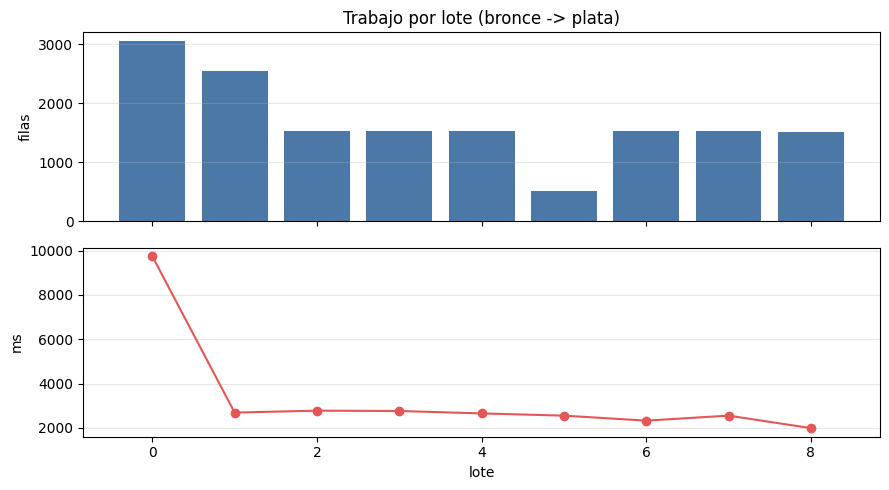

In [17]:
import matplotlib.pyplot as plt

lotes  = sorted(progreso.get("bronce_a_plata", {}).values(), key=lambda p: p["batchId"])
ids    = [p["batchId"] for p in lotes]
filas  = [p["numInputRows"] for p in lotes]
tiempo = [p["durationMs"].get("triggerExecution", 0) for p in lotes]

print(f"lotes procesados   {len(lotes)}")
print(f"filas en total     {sum(filas):,}")
print(f"filas por lote     {sum(filas)/max(len(filas),1):.0f} de media, {max(filas, default=0)} maximo")
print(f"tiempo por lote    {sum(tiempo)/max(len(tiempo),1):.0f} ms de media, {max(tiempo, default=0)} ms maximo")

fig, (a1, a2) = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
a1.bar(ids, filas, color="#4c78a8")
a1.set_ylabel("filas"); a1.grid(axis="y", alpha=.3)
a1.set_title("Trabajo por lote (bronce -> plata)")
a2.plot(ids, tiempo, marker="o", color="#e45756")
a2.set_ylabel("ms"); a2.set_xlabel("lote"); a2.grid(axis="y", alpha=.3)
plt.tight_layout()
plt.savefig(AQUI / "rendimiento.png", dpi=120)
plt.show()

---
## 10. Conclusiones

Lo que se ha construido y dónde está cada cosa que pedía el enunciado:

| Lo que pedía el enunciado | Dónde está |
|---|---|
| Leer telemetría simulada en streaming | Sección 3, `readStream` sobre `lake/landing/` |
| Parsear el JSON | Sección 3, esquema declarado a mano |
| Limpiar anomalías | Sección 4, seis reglas + tabla de cuarentena |
| Tabla Delta particionada por ciudad | Sección 4, `partitionBy("city")`; comprobado en 7.2 |

Limitaciones:

`foreachBatch` garantiza *al menos una vez*, no *exactamente una vez*. Si el proceso
se cayera después de escribir plata pero antes de confirmar el avance, ese lote se
reescribiría al reiniciar. Como cada evento tiene identificador único y los
duplicados se quitan antes, en la práctica no ocurre.

El watermark descarta eventos sin avisar. Es el precio de que la memoria de
duplicados no crezca sin límite, y por eso la comprobación 7.1 mide esa diferencia
en vez de dar la suma por buena.

Particionar por ciudad funciona porque son cinco valores. Por vehículo (1.590) o por
segundo darían miles de carpetas con un fichero minúsculo dentro.

In [18]:
spark.stop()
print("Spark cerrado.")

Spark cerrado.
